# Constructor University peer benchmark

A UniversityScope case study by Blessing Sekeramavi. Run the four code cells in order. Place `times_higher_education_rankings.csv` beside the notebook, or upload it when prompted in Colab.

**Question:** How does Constructor compare with five ranked German institutions selected by rank-band proximity?

The sample is a screening comparison. Institution size, subject mix and mission are not matched. The ranking edition remains unverified. Original rank bands and score intervals remain intact.


In [ ]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

benchmark_csv=Path('times_higher_education_rankings.csv')
if not benchmark_csv.exists():
    try:
        from google.colab import files
        uploaded=files.upload()
        candidates=[name for name in uploaded if name.lower().endswith('.csv')]
        if not candidates: raise ValueError('Choose the original rankings CSV.')
        benchmark_csv=Path(candidates[0])
    except ImportError:
        raise FileNotFoundError('Place times_higher_education_rankings.csv beside this notebook.')
benchmark_raw=pd.read_csv(benchmark_csv)
display(benchmark_raw.loc[benchmark_raw['name'].str.contains('Constructor|Jacobs',case=False,na=False),['name','location','rank']])


## 1. Select the target and peers
Retain ranked institutions in Germany, exclude Constructor, then sort by absolute distance between rank-band lower bounds. Break ties alphabetically and take five. This rule uses no component score to choose favourable peers.


In [ ]:
def benchmark_bounds(value):
    if pd.isna(value): return (np.nan,np.nan)
    text=str(value).strip().lstrip('=').strip()
    if re.fullmatch(r'\d+(?:\.\d+)?',text): return (float(text),float(text))
    match=re.fullmatch(r'(\d+(?:\.\d+)?)\s*[-–—]\s*(\d+(?:\.\d+)?)',text)
    if match:
        low,high=map(float,match.groups())
        return (low,high) if low<=high else (np.nan,np.nan)
    if re.fullmatch(r'\d+\s*\+',text): return (float(text.rstrip('+').strip()),np.nan)
    return (np.nan,np.nan)

benchmark_df=benchmark_raw.copy()
benchmark_df['rank_original']=benchmark_df['rank'].astype(str)
benchmark_df['rank_lower']=benchmark_df['rank'].map(lambda x:benchmark_bounds(x)[0])
disabled=benchmark_df.get('disabled',pd.Series(False,index=benchmark_df.index)).astype(str).str.lower().str.strip().isin(['true','1','1.0'])
benchmark_df['eligible']=benchmark_df.rank_lower.notna() & ~disabled
metrics=['teaching','research','citations','industry_income','international_outlook']
metric_labels=['Teaching','Research','Citations','Industry income','International outlook']
for metric in metrics:
    raw_col='scores_'+metric
    if raw_col not in benchmark_df: raise ValueError('Required source field missing: '+raw_col)
    bounds=benchmark_df[raw_col].map(benchmark_bounds)
    benchmark_df[metric+'_lower']=[x[0] for x in bounds]
    benchmark_df[metric+'_upper']=[x[1] for x in bounds]
    valid=benchmark_df[metric+'_lower'].between(0,100)&benchmark_df[metric+'_upper'].between(0,100)
    benchmark_df.loc[~valid,[metric+'_lower',metric+'_upper']]=np.nan
target_rows=benchmark_df[benchmark_df['name'].eq('Constructor University')&benchmark_df.eligible]
if len(target_rows)!=1: raise ValueError('Expected exactly one ranked Constructor University record.')
benchmark_target=target_rows.iloc[0]
benchmark_candidates=benchmark_df[benchmark_df.location.eq(benchmark_target.location)&benchmark_df.eligible&benchmark_df['name'].ne(benchmark_target['name'])].copy()
benchmark_candidates['rank_band_distance']=(benchmark_candidates.rank_lower-benchmark_target.rank_lower).abs()
benchmark_peers=benchmark_candidates.sort_values(['rank_band_distance','name']).head(5)
if len(benchmark_peers)<3:raise ValueError('Not enough eligible peers for this comparison.')
display(benchmark_peers[['name','location','rank_original','rank_band_distance']])
summary=[]
for metric,label in zip(metrics,metric_labels):
    median=benchmark_peers[metric+'_lower'].median()
    median_upper=benchmark_peers[metric+'_upper'].median()
    target_lower=benchmark_target[metric+'_lower'];target_upper=benchmark_target[metric+'_upper']
    summary.append({'Dimension':label,'Constructor lower':target_lower,'Constructor upper':target_upper,'Peer median lower':median,'Peer median upper':median_upper,'Gap lower-bound scores':target_lower-median,'Peer count':benchmark_peers[metric+'_lower'].count()})
benchmark_summary=pd.DataFrame(summary)
display(benchmark_summary.round(1))


## 2. Compare scores and gaps
The first chart compares Constructor with the peer median. The second shows Constructor minus that median. Units are component-score points on a 0–100 scale. Any ranged values use their lower endpoints, with upper endpoints retained in the table above. These source component scores are not statistical confidence intervals.


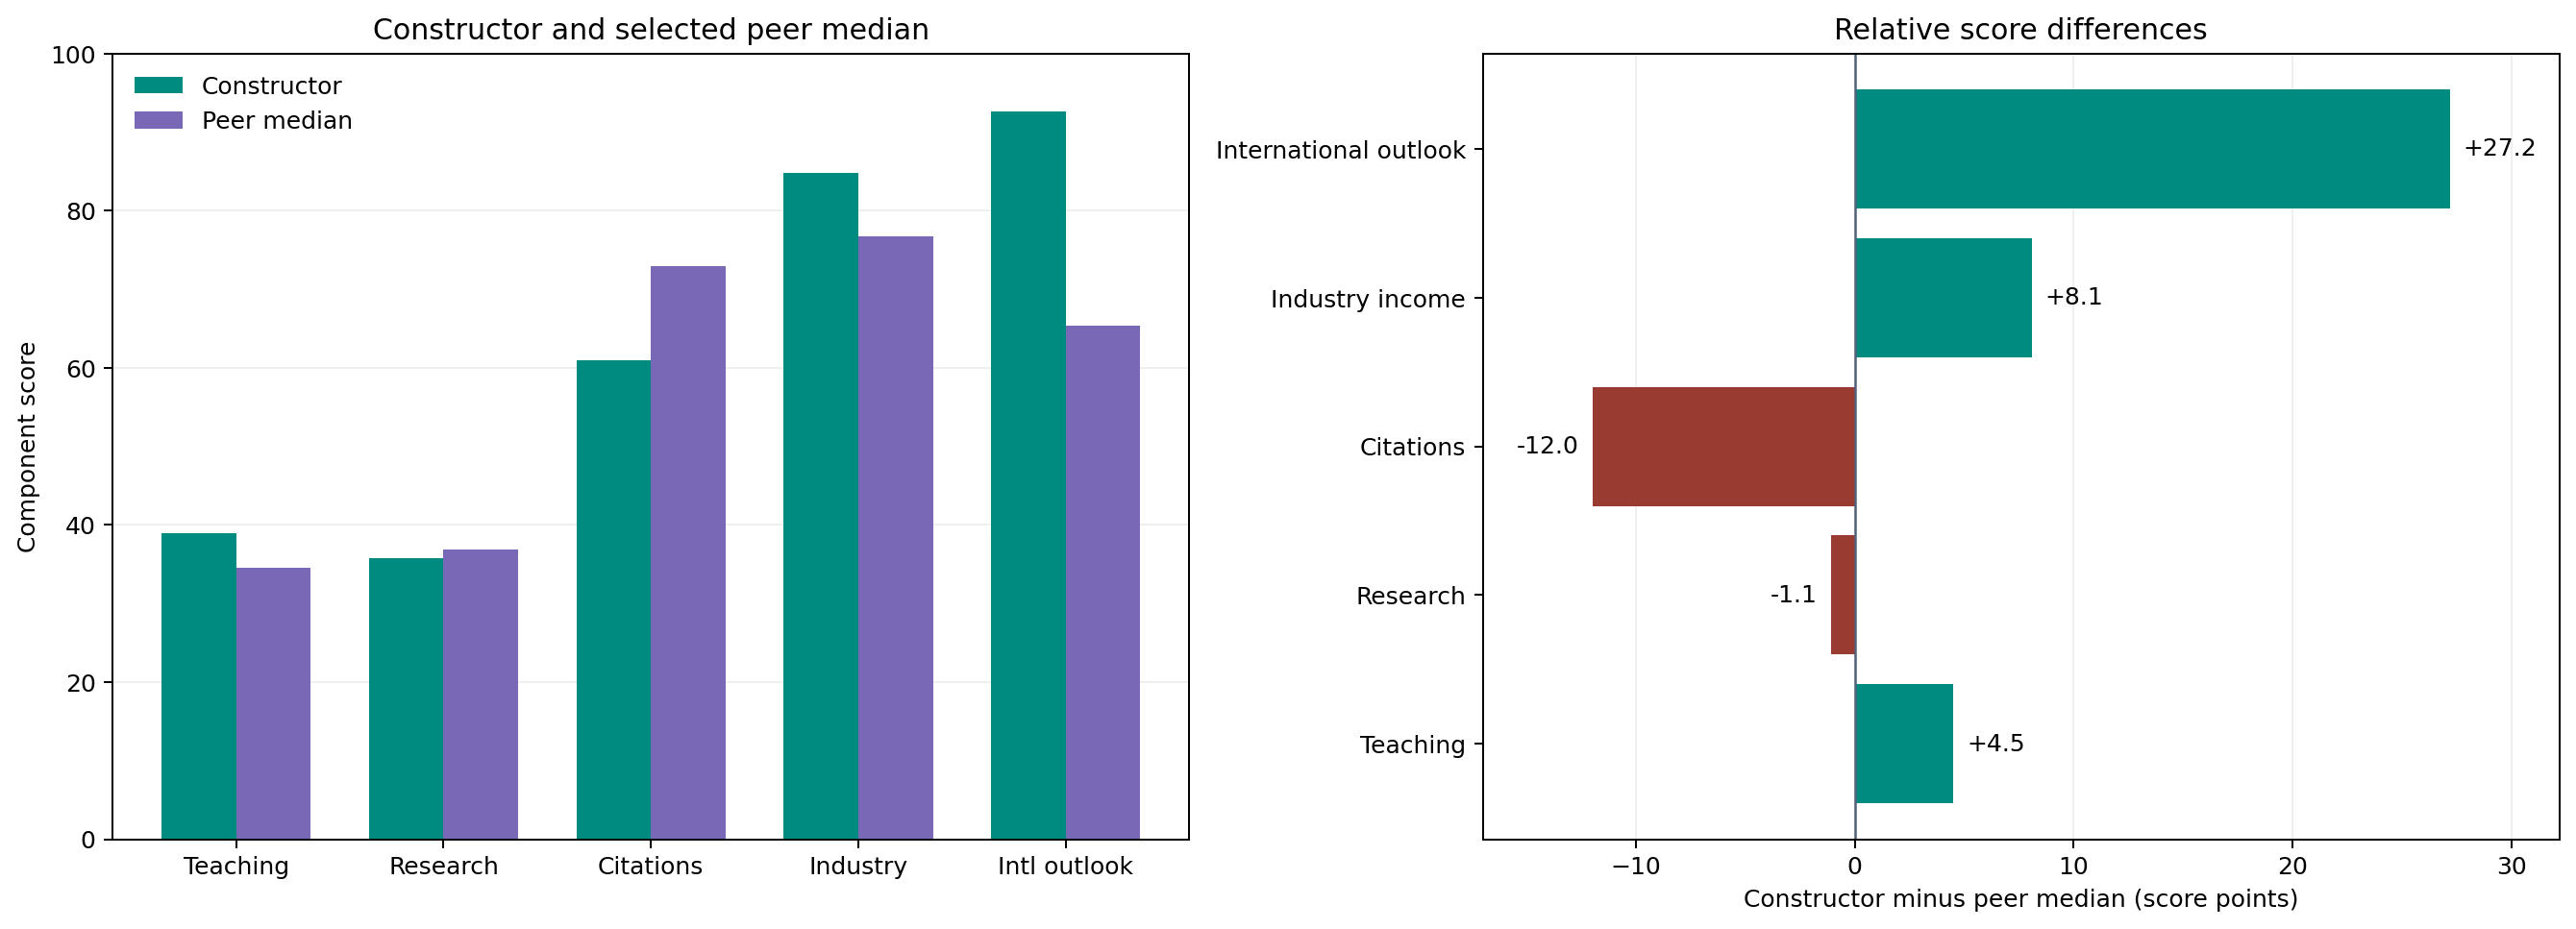

In [ ]:
plt.style.use('default')
fig,axes=plt.subplots(1,2,figsize=(15,5.5))
x=np.arange(len(metric_labels));width=.36
axes[0].bar(x-width/2,benchmark_summary['Constructor lower'],width,label='Constructor',color='#008B80')
axes[0].bar(x+width/2,benchmark_summary['Peer median lower'],width,label='Peer median',color='#7868B5')
axes[0].set_xticks(x,['Teaching','Research','Citations','Industry','Intl outlook'])
axes[0].set_ylim(0,100);axes[0].set_ylabel('Component score');axes[0].set_title('Constructor and selected peer median');axes[0].legend(frameon=False)
gap=benchmark_summary['Gap lower-bound scores']
axes[1].barh(metric_labels,gap,color=['#008B80' if v>=0 else '#9A3B32' for v in gap])
axes[1].axvline(0,color='#52627A',linewidth=1)
axes[1].set_xlim(min(-15,float(gap.min())-5),max(30,float(gap.max())+5))
axes[1].set_xlabel('Constructor minus peer median (score points)');axes[1].set_title('Relative score differences')
for i,v in enumerate(gap):
    if pd.notna(v):axes[1].text(v+(0.6 if v>=0 else -0.6),i,f'{v:+.1f}',va='center',ha='left' if v>=0 else 'right')
for ax in axes:ax.grid(axis='y' if ax is axes[0] else 'x',alpha=.2);ax.set_axisbelow(True)
fig.tight_layout();fig.savefig('Constructor_Benchmark_Charts.png',dpi=180,bbox_inches='tight');plt.show()
available=benchmark_summary.dropna(subset=['Gap lower-bound scores'])
strong=available.loc[available['Gap lower-bound scores'].idxmax()];weak=available.loc[available['Gap lower-bound scores'].idxmin()]
display(Markdown(f"**Largest positive difference:** {strong['Dimension']}, {strong['Gap lower-bound scores']:+.1f} score points.\n\n**Largest negative difference:** {weak['Dimension']}, {weak['Gap lower-bound scores']:+.1f} score points.\n\n**Interpretation limit:** this comparison controls only country and rank-band proximity. It does not establish equivalent institutional missions or explain the causes of score differences."))


## 3. Report outputs

[Excel workbook](Constructor_University_Benchmark.xlsx) · [Five-slide briefing](Constructor_University_Benchmark_Briefing.pptx) · [Method and findings](README.md)

The workbook contains linked formulas, two editable charts, six selected source records and a method sheet. The briefing presents the peer selection, score comparison and interpretation limits. Download these files from GitHub to open them.

The prepared reports reflect the checked 16 October 2026 snapshot. Rerunning this notebook recalculates the analysis and saves two CSVs and a PNG; it does not automatically rebuild the workbook or briefing.


In [ ]:
benchmark_summary.to_csv('Constructor_Benchmark_Summary.csv',index=False)
selected_records=pd.concat([benchmark_target.to_frame().T,benchmark_peers])
selected_records[['name','location','rank_original']+[m+'_'+bound for m in metrics for bound in ['lower','upper']]].to_csv('Constructor_Benchmark_Selected_Records.csv',index=False)
print('Saved: Constructor_Benchmark_Summary.csv, Constructor_Benchmark_Selected_Records.csv, Constructor_Benchmark_Charts.png')
